In [18]:
#Bank Marketing: Which customer characteristics and campaign-related factors are associated with the success of a bank marketing campaign?

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import binom, poisson, norm

In [20]:
df=pd.read_csv('bank-full.csv', sep=';')  #using sep=';' because panda wasn't reconizing the separator used in my csv file.
print(f"Total: {len(df)}")

Total: 45211


In [21]:
with open("bank-full.csv", "r", encoding="utf-8") as arquivo:
    total_entradas = sum(1 for linha in arquivo)

print(f"O arquivo tem {total_entradas} entradas.")

O arquivo tem 45212 entradas.


In [22]:
df.head(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


In [23]:
df.tail(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45201,53,management,married,tertiary,no,583,no,no,cellular,17,nov,226,1,184,4,success,yes
45202,34,admin.,single,secondary,no,557,no,no,cellular,17,nov,224,1,-1,0,unknown,yes
45203,23,student,single,tertiary,no,113,no,no,cellular,17,nov,266,1,-1,0,unknown,yes
45204,73,retired,married,secondary,no,2850,no,no,cellular,17,nov,300,1,40,8,failure,yes
45205,25,technician,single,secondary,no,505,no,yes,cellular,17,nov,386,2,-1,0,unknown,yes
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [24]:
df.shape

(45211, 17)

In [25]:
#Non-null: Not missing values
#int64: Integer (Whole number)
#Object: Text or categorical data.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [26]:
df.dtypes

age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

In [27]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [28]:
print("Column names:")
df.columns.tolist()


Column names:


['age',
 'job',
 'marital',
 'education',
 'default',
 'balance',
 'housing',
 'loan',
 'contact',
 'day',
 'month',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'y']

In [29]:
categorical_vars = df.select_dtypes(include="object").columns.tolist()
numerical_vars = df.select_dtypes(include="number").columns.tolist()

categorical_vars = df.select_dtypes(include="object").columns.tolist()
numerical_vars = df.select_dtypes(include="number").columns.tolist()

print("Categorical variables:")
print(categorical_vars)

print("\nNumerical variables:")
print(numerical_vars)


Categorical variables:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']

Numerical variables:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


In [30]:
selected_vars = ["age", "balance", "duration", "campaign", "previous"]
print(df[selected_vars].describe().round(2))


            age    balance  duration  campaign  previous
count  45211.00   45211.00  45211.00  45211.00  45211.00
mean      40.94    1362.27    258.16      2.76      0.58
std       10.62    3044.77    257.53      3.10      2.30
min       18.00   -8019.00      0.00      1.00      0.00
25%       33.00      72.00    103.00      1.00      0.00
50%       39.00     448.00    180.00      2.00      0.00
75%       48.00    1428.00    319.00      3.00      0.00
max       95.00  102127.00   4918.00     63.00    275.00


In [12]:
categorical_cols = df.select_dtypes(
    include=["object"]
).columns

In [13]:
for col in categorical_cols:
    unknown_count = (df[col] == "unknown").sum()

    if unknown_count > 0:
        print(
            f"{col}: {unknown_count} unknown values"
        )

job: 288 unknown values
education: 1857 unknown values
contact: 13020 unknown values
poutcome: 36959 unknown values


In [14]:
# Create an empty list to store the results
unknown_results = []

# Check each categorical column
for col in df.select_dtypes(include="object").columns:

    # Count the unknown values
    count = (df[col] == "unknown").sum()

    # Calculate the percentage
    percentage = (count / len(df)) * 100

    # Save the results if unknown values exist
    if count > 0:
        unknown_results.append({
            "Column": col,
            "Unknown Count": count,
            "Unknown Percentage (%)": round(percentage, 2)
        })

# Convert the results into a table
unknown_summary = pd.DataFrame(unknown_results)

# Display the table
display(unknown_summary)

,Column,Unknown Count,Unknown Percentage (%)
0,job,288,0.64
1,education,1857,4.11
2,contact,13020,28.80
3,poutcome,36959,81.75


In [15]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

# Display the result
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [16]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


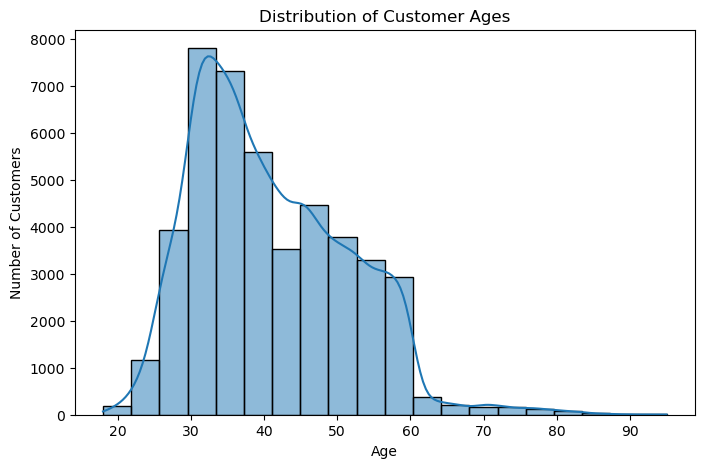

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Distribution of Customer Ages")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

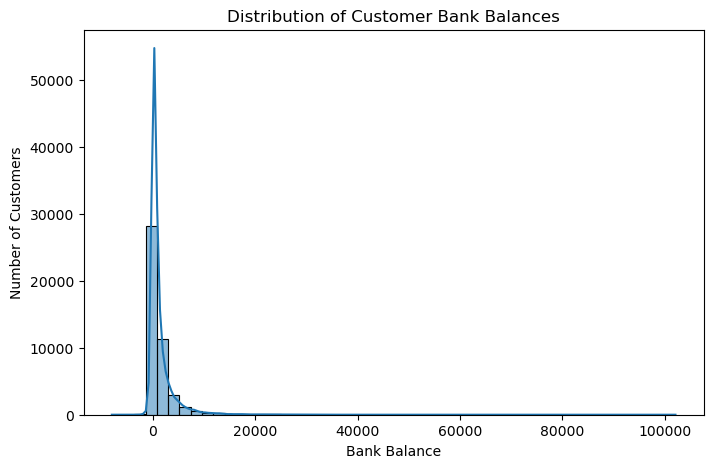

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="balance", bins=50, kde=True)

plt.title("Distribution of Customer Bank Balances")
plt.xlabel("Bank Balance")
plt.ylabel("Number of Customers")
plt.show()

In [19]:
# Calculate the main balance statistics
print("Mean balance:", round(df["balance"].mean(), 2))
print("Median balance:", round(df["balance"].median(), 2))
print("Minimum balance:", df["balance"].min())
print("Maximum balance:", df["balance"].max())

# Count negative, zero, and positive balances
balance_categories = pd.Series({
    "Negative balance": (df["balance"] < 0).sum(),
    "Zero balance": (df["balance"] == 0).sum(),
    "Positive balance": (df["balance"] > 0).sum()
})

# Calculate percentages
balance_percentages = (
    balance_categories / len(df) * 100
).round(2)

# Combine results into a table
balance_summary = pd.DataFrame({
    "Number of Customers": balance_categories,
    "Percentage (%)": balance_percentages
})

display(balance_summary)

Mean balance: 1362.27
Median balance: 448.0
Minimum balance: -8019
Maximum balance: 102127


,Number of Customers,Percentage (%)
Negative balance,3766,8.33
Zero balance,3514,7.77
Positive balance,37931,83.90


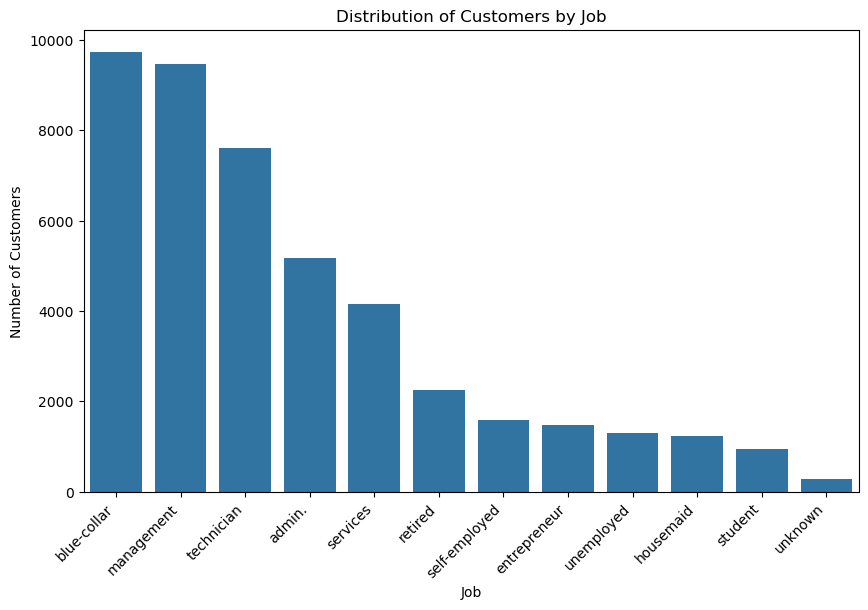

In [20]:
plt.figure(figsize=(10, 6))
#using COUNTPLOT because the data JOB is not numerical
sns.countplot(data=df, x="job", order=df["job"].value_counts().index)

# Add title and labels
plt.title("Distribution of Customers by Job")
plt.xlabel("Job")
plt.ylabel("Number of Customers")

# Rotate the job labels for better readability
plt.xticks(rotation=45, ha="right")

# Display the chart
plt.show()

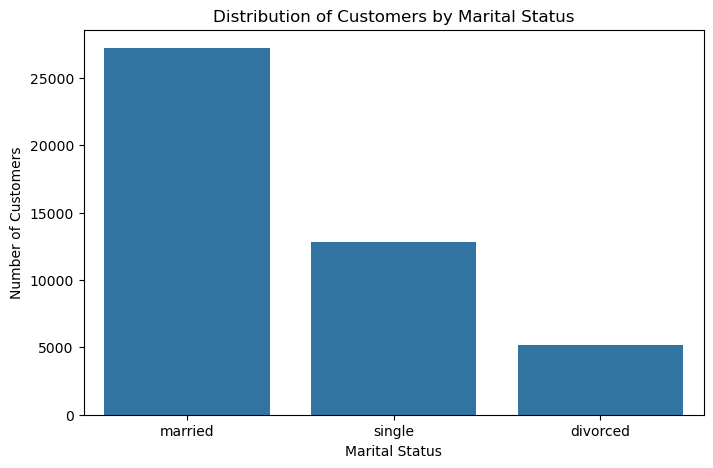

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="marital", order=df["marital"].value_counts().index)

plt.title("Distribution of Customers by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Number of Customers")

plt.show()

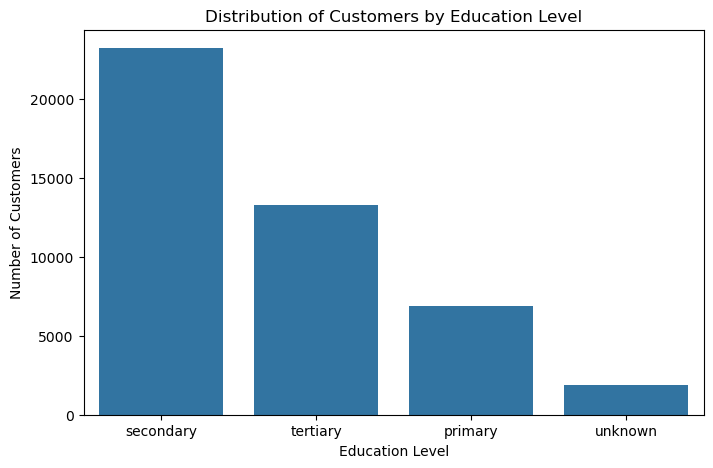

In [22]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="education", order=df["education"].value_counts().index)

plt.title("Distribution of Customers by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Number of Customers")
plt.show()

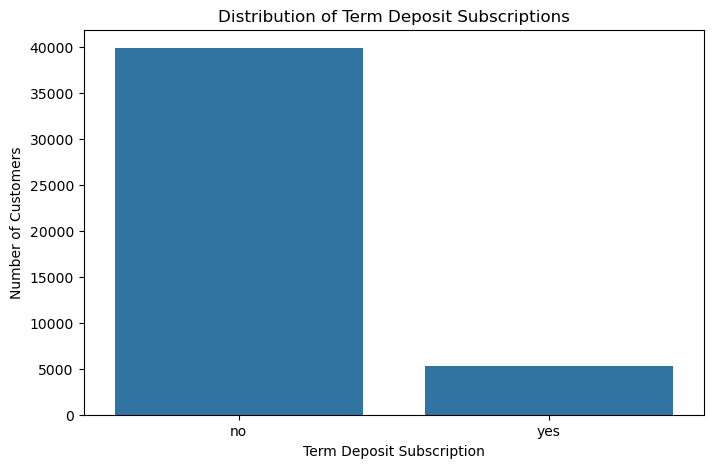

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="y",
    order=df["y"].value_counts().index
)

plt.title("Distribution of Term Deposit Subscriptions")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")
plt.show()

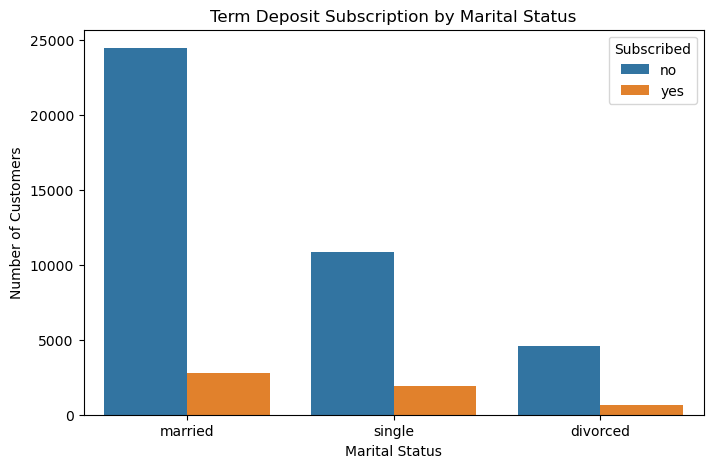

In [24]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="marital",
    hue="y",
    order=df["marital"].value_counts().index
)

plt.title("Term Deposit Subscription by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Number of Customers")
plt.legend(title="Subscribed")
plt.show()

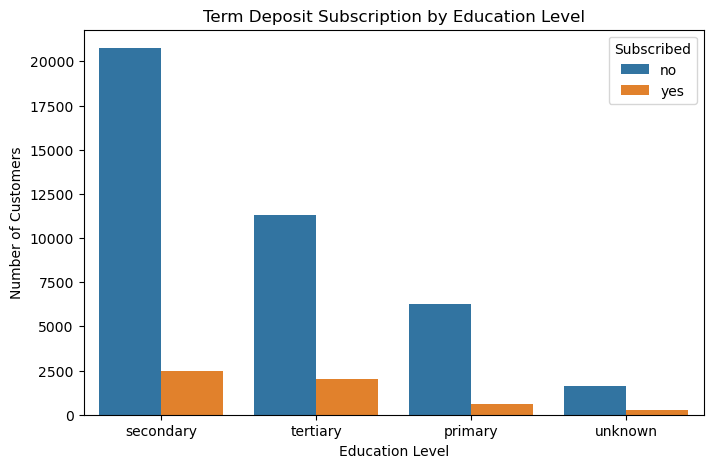

In [25]:

# Create the figure
plt.figure(figsize=(8, 5))

# Generate the grouped bar chart
sns.countplot(
    data=df,
    x="education",
    hue="y",
    order=df["education"].value_counts().index
)

plt.title("Term Deposit Subscription by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Number of Customers")
plt.legend(title="Subscribed")
plt.show()

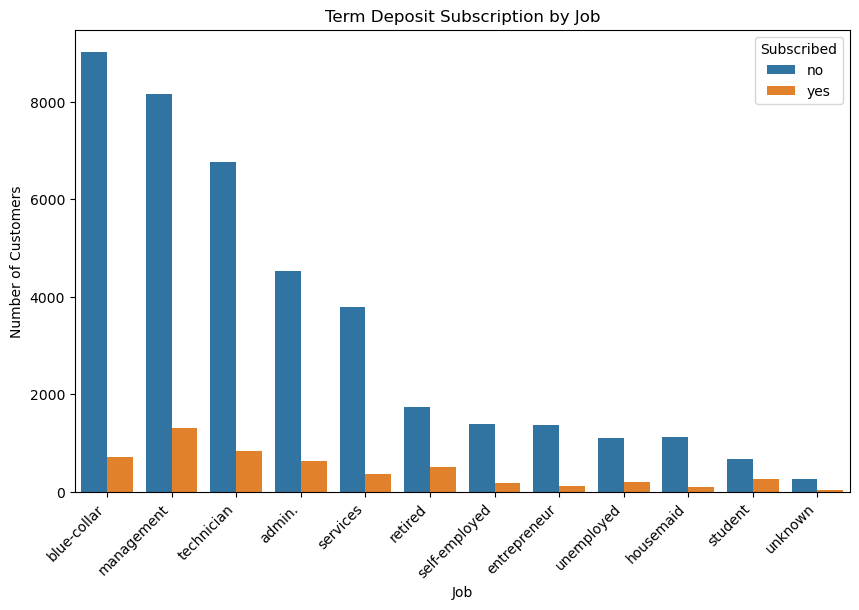

In [26]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="job",
    hue="y",
    order=df["job"].value_counts().index
)

plt.title("Term Deposit Subscription by Job")
plt.xlabel("Job")
plt.ylabel("Number of Customers")
plt.legend(title="Subscribed")
plt.xticks(rotation=45, ha="right")

plt.show()

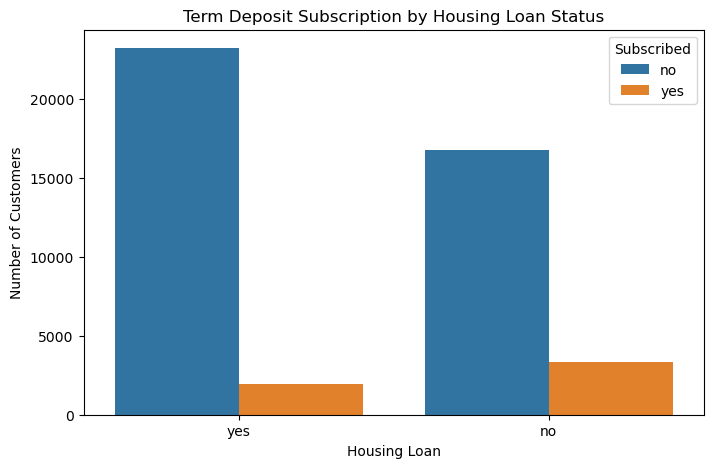

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="housing",
    hue="y",
    order=df["housing"].value_counts().index
)

plt.title("Term Deposit Subscription by Housing Loan Status")
plt.xlabel("Housing Loan")
plt.ylabel("Number of Customers")
plt.legend(title="Subscribed")
plt.show()

In [28]:
#DO I NEED TO DO THIS AFTER EVERY TABLE?

housing_subscription = pd.crosstab(
    df["housing"],
    df["y"],
    normalize="index"
) * 100

housing_subscription = housing_subscription.round(2)

housing_subscription = housing_subscription.sort_values(
    by="yes",
    ascending=False
)

display(housing_subscription)

y,no,yes
housing,,
no,83.3,16.7
yes,92.3,7.7


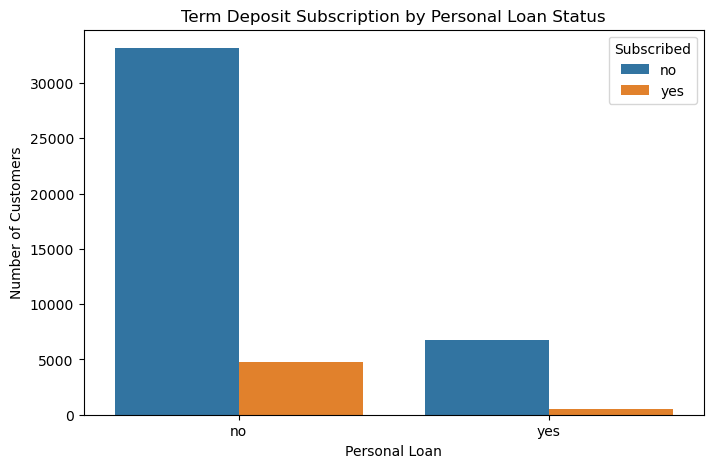

In [29]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="loan",
    hue="y",
    order=df["loan"].value_counts().index
)

plt.title("Term Deposit Subscription by Personal Loan Status")
plt.xlabel("Personal Loan")
plt.ylabel("Number of Customers")
plt.legend(title="Subscribed")
plt.show()

In [30]:
loan_subscription = pd.crosstab(
    df["loan"],
    df["y"],
    normalize="index"
) * 100

loan_subscription = loan_subscription.round(2)

loan_subscription = loan_subscription.sort_values(
    by="yes",
    ascending=False
)

display(loan_subscription)

y,no,yes
loan,,
no,87.34,12.66
yes,93.32,6.68


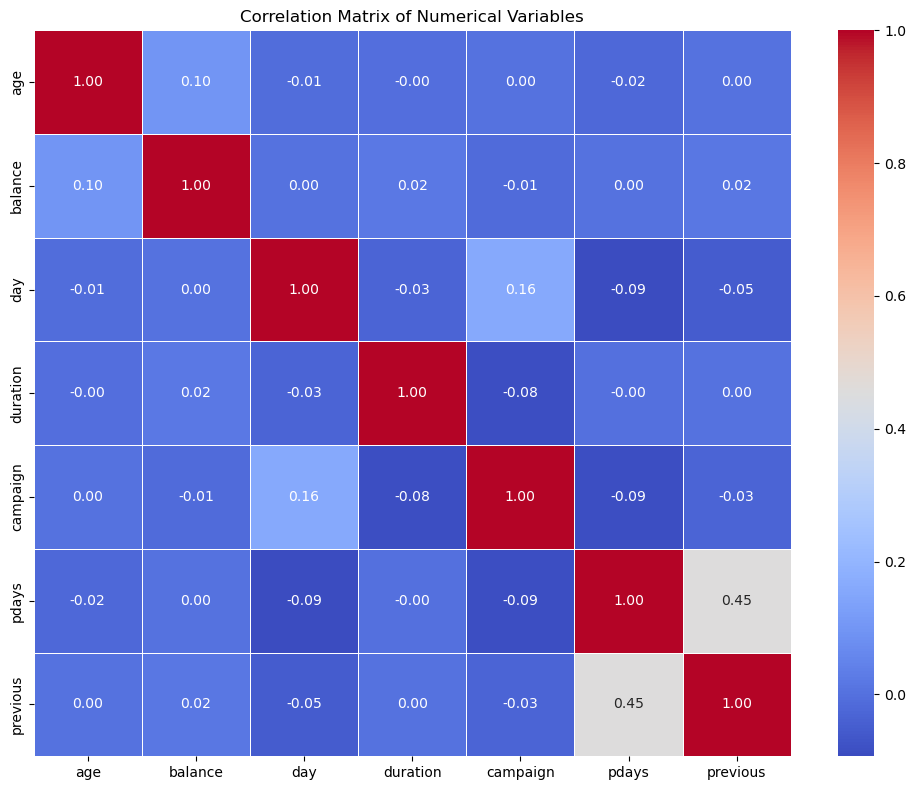

In [31]:
#MAKING CORRELATION MATRIX OF NUMERICAL VARIABLES

numerical_df = df.select_dtypes(include="number")

correlation_matrix = numerical_df.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Variables")

plt.tight_layout()
plt.savefig("correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [32]:
display(correlation_matrix.round(2))

,age,balance,day,duration,campaign,pdays,previous
age,1.00,0.10,-0.01,-0.00,0.00,-0.02,0.00
balance,0.10,1.00,0.00,0.02,-0.01,0.00,0.02
day,-0.01,0.00,1.00,-0.03,0.16,-0.09,-0.05
duration,-0.00,0.02,-0.03,1.00,-0.08,-0.00,0.00
campaign,0.00,-0.01,0.16,-0.08,1.00,-0.09,-0.03
pdays,-0.02,0.00,-0.09,-0.00,-0.09,1.00,0.45
previous,0.00,0.02,-0.05,0.00,-0.03,0.45,1.00
